# Retail Growth and Profitability Comparison

This project compares Amazon North America and Walmart U.S. over 2019-2024, using 2019 as the pre-pandemic reference. Four modules turn official segment data into a SQLite database, annual metrics, stage summaries, a five-year sales CAGR, and three charts with an HTML report.

The notebook contains reusable Python logic. `config.json` contains research settings, labels, source links and business commentary; `financial_data.csv` contains twelve manually transcribed financial records from free official annual reports. To compare other businesses within the same financial-data structure, update both input files, including the source references and commentary. Changing company names alone does not supply new company data.

Keep the notebook, JSON and input CSV together. Open the notebook from that folder and run all cells from top to bottom with pandas and matplotlib installed. The path code supports starting Python either inside this folder or in its parent JupyterProject folder. If your IDE starts in another location, set `PROJECT_DIRECTORY` in Module 01 Cell 03 to this folder. All generated tables, images, the SQLite database and HTML report go into `retail_simple_output` inside that folder. Rerunning replaces the generated outputs.

The six annual observations per segment provide five growth intervals. Amounts are nominal USD millions. Fiscal windows are approximately paired with a one-month shift; the actual dates are displayed. This is a descriptive comparison, not a causal estimate of the pandemic's effect. The accompanying PDF presents the core findings; rerunning the notebook regenerates the HTML report, not the PDF.


## Module 01: Research Configuration

Load the study content from `config.json` and store it in a small `StudyConfig` object. The file sets the businesses, fiscal-year offsets, study years, stages, chart appearance and written context. Later modules use these shared settings instead of embedding company names in calculation rules.


In [1]:
# Cell 01: Import Libraries

import json
import sqlite3
from pathlib import Path
from html import escape

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:
# Cell 02: Define StudyConfig

class StudyConfig:
    def __init__(self, settings):
        self.title = settings["title"]
        self.question = settings["question"]
        self.start_year = settings["start_year"]
        self.end_year = settings["end_year"]
        self.base_year = settings["base_year"]
        self.units = settings["units"]
        self.stages = settings["stages"]
        self.charts = settings["charts"]
        self.notes = settings["notes"]
        self.label_years = settings["label_years"]
        self.metric_columns = settings["metric_columns"]
        self.annual_columns = settings["annual_columns"]
        self.business_context = settings["business_context"]
        self.context_sources = settings["context_sources"]


In [3]:
# Cell 03: Load the Research Settings

PROJECT_DIRECTORY = Path.cwd()
if not (PROJECT_DIRECTORY / "config.json").exists():
    PROJECT_DIRECTORY = PROJECT_DIRECTORY / "Amazon_vs_Walmart"
with (PROJECT_DIRECTORY / "config.json").open(encoding="utf-8") as file:
    settings = json.load(file)

config = StudyConfig(settings)
sources = settings["sources"]
OUTPUT_DIRECTORY = PROJECT_DIRECTORY / "retail_simple_output"
print(config.title)


Retail Growth and Profitability Comparison: Amazon North America and Walmart U.S., 2019-2024


## Module 02: Data and Database Management

Read `financial_data.csv` into `raw_df`. The cleaning functions convert amount strings to numbers, preserve bracketed losses, apply the fiscal-year offsets, and attach stages and source references. `clean_df` retains the original strings and actual reporting dates.

Save the cleaned records to the SQLite `financial_records` table, read them back into `financial_df`, and export them to CSV. `DatabaseManager.query()` also accepts a SQL statement; Module 03 uses it for a real aggregation query. No paid data service or live API is required.


In [4]:
# Cell 01: Define Cleaning Functions and DatabaseManager

def clean_number(text):
    text = text.replace(",", "")
    text = text.replace("(", "-").replace(")", "")
    return float(text)


def clean_data(raw_df, config, sources):
    rows = []
    for row in raw_df.to_dict("records"):
        unit = config.units[row["unit_id"]]
        year = row["fiscal_year"] + unit["year_offset"]
        if config.start_year <= year <= config.end_year:
            source = sources[row["source_id"]]
            row["company"] = unit["company"]
            row["segment"] = unit["segment"]
            row["analysis_year"] = year
            row["net_sales"] = clean_number(row["sales_raw"])
            row["operating_income"] = clean_number(row["income_raw"])
            row["currency"] = "USD"
            row["amount_unit"] = "millions"
            row["source_url"] = source["url"]
            row["source_section"] = source["section"] + "; fiscal " + str(row["fiscal_year"]) + " column"
            row["accessed_date"] = source["accessed_date"]
            row["date_basis"] = unit["date_basis"]
            for stage in config.stages:
                if stage["start"] <= year <= stage["end"]:
                    row["comparison_stage"] = stage["name"]
            rows.append(row)
    return pd.DataFrame(rows)


class DatabaseManager:
    def __init__(self, folder):
        self.folder = Path(folder)
        self.folder.mkdir(parents=True, exist_ok=True)
        self.database_path = self.folder / "retail_comparison.sqlite"

    def save(self, df, table_name):
        connection = sqlite3.connect(self.database_path)
        df.to_sql(table_name, connection, if_exists="replace", index=False)
        connection.close()

    def query(self, sql):
        connection = sqlite3.connect(self.database_path)
        df = pd.read_sql_query(sql, connection)
        connection.close()
        return df

    def read(self, table_name):
        return self.query("SELECT * FROM " + table_name)


In [5]:
# Cell 02: Read and Clean the Financial Data

raw_df = pd.read_csv(PROJECT_DIRECTORY / "financial_data.csv",
                     dtype={"sales_raw": str, "income_raw": str})
clean_df = clean_data(raw_df, config, sources)
display(clean_df[["company", "segment", "analysis_year", "fiscal_year",
                  "period_start", "period_end", "net_sales", "operating_income"]])


,company,segment,analysis_year,fiscal_year,period_start,period_end,net_sales,operating_income
0,"Amazon.com, Inc.",North America,2019,2019,2019-01-01,2019-12-31,170773.0,7033.0
1,"Amazon.com, Inc.",North America,2020,2020,2020-01-01,2020-12-31,236282.0,8651.0
2,"Amazon.com, Inc.",North America,2021,2021,2021-01-01,2021-12-31,279833.0,7271.0
3,"Amazon.com, Inc.",North America,2022,2022,2022-01-01,2022-12-31,315880.0,-2847.0
4,"Amazon.com, Inc.",North America,2023,2023,2023-01-01,2023-12-31,352828.0,14877.0
5,"Amazon.com, Inc.",North America,2024,2024,2024-01-01,2024-12-31,387497.0,24967.0
6,Walmart Inc.,Walmart U.S.,2019,2020,2019-02-01,2020-01-31,341004.0,17380.0
7,Walmart Inc.,Walmart U.S.,2020,2021,2020-02-01,2021-01-31,369963.0,19116.0
8,Walmart Inc.,Walmart U.S.,2021,2022,2021-02-01,2022-01-31,393247.0,21587.0
9,Walmart Inc.,Walmart U.S.,2022,2023,2022-02-01,2023-01-31,420553.0,20620.0


In [6]:
# Cell 03: Save and Read the Financial Records

database = DatabaseManager(OUTPUT_DIRECTORY)
database.save(clean_df, "financial_records")
financial_df = database.read("financial_records")
financial_df.to_csv(OUTPUT_DIRECTORY / "financial_records.csv", index=False)
print(f"Financial records saved: {len(financial_df)}")


Financial records saved: 12


## Module 03: Metrics and Comparative Analysis

Calculate annual sales growth, operating margin and the reference-year sales index for each segment. Keep 2019 annual growth missing because 2018 sales are not in the input. A separate method calculates full-window sales CAGR using the first and last selected years: 2019-2024 has five compounding intervals, not six.

Summarize the study stages with arithmetic means and valid-year counts. Then run a SQL `GROUP BY` query with `AVG` and `COUNT` directly against SQLite to obtain stage sales-growth means. SQLite excludes NULL growth values, so the 2019 baseline has no growth average and zero valid growth years. Save results to database tables and CSV files for reporting.


In [7]:
# Cell 01: Define MetricCalculator

class MetricCalculator:
    def __init__(self, config):
        self.config = config

    def calculate(self, financial_df):
        rows = []
        for unit_id in self.config.units:
            unit_df = financial_df[financial_df["unit_id"] == unit_id]
            unit_df = unit_df.sort_values("analysis_year")
            base = unit_df[unit_df["analysis_year"] == self.config.base_year].iloc[0]
            base_margin = base["operating_income"] / base["net_sales"] * 100
            previous_sales = None
            for row in unit_df.to_dict("records"):
                sales = row["net_sales"]
                margin = row["operating_income"] / sales * 100
                row["operating_margin_pct"] = margin
                row["sales_index"] = sales / base["net_sales"] * 100
                row["sales_change_from_base_pct"] = (sales / base["net_sales"] - 1) * 100
                row["margin_change_from_base_pp"] = margin - base_margin
                row["sales_growth_pct"] = None
                if previous_sales is not None:
                    row["sales_growth_pct"] = (sales / previous_sales - 1) * 100
                rows.append(row)
                previous_sales = sales
        return pd.DataFrame(rows)

    def sales_summary(self, metrics_df):
        rows = []
        for unit_id in self.config.units:
            selected = metrics_df[metrics_df["unit_id"] == unit_id]
            selected = selected.sort_values("analysis_year")
            first = selected.iloc[0]
            last = selected.iloc[-1]
            intervals = int(last["analysis_year"] - first["analysis_year"])
            cagr = ((last["net_sales"] / first["net_sales"]) ** (1 / intervals) - 1) * 100
            rows.append({"unit_id": unit_id, "company": first["company"],
                         "segment": first["segment"], "start_year": first["analysis_year"],
                         "end_year": last["analysis_year"], "growth_intervals": intervals,
                         "start_sales": first["net_sales"], "end_sales": last["net_sales"],
                         "sales_cagr_pct": cagr})
        return pd.DataFrame(rows)


In [8]:
# Cell 02: Calculate and Save Annual Metrics and CAGR

calculator = MetricCalculator(config)
metrics_df = calculator.calculate(financial_df)
database.save(metrics_df, "annual_metrics")
metrics_df = database.read("annual_metrics")
sales_summary_df = calculator.sales_summary(metrics_df)
database.save(sales_summary_df, "sales_summary")
display(metrics_df[config.annual_columns].round(2))
display(sales_summary_df.round(2))


,company,segment,analysis_year,fiscal_year,period_start,period_end,net_sales,operating_income,sales_growth_pct,operating_margin_pct,sales_index
0,"Amazon.com, Inc.",North America,2019,2019,2019-01-01,2019-12-31,170773.0,7033.0,NaN,4.12,100.00
1,"Amazon.com, Inc.",North America,2020,2020,2020-01-01,2020-12-31,236282.0,8651.0,38.36,3.66,138.36
2,"Amazon.com, Inc.",North America,2021,2021,2021-01-01,2021-12-31,279833.0,7271.0,18.43,2.60,163.86
3,"Amazon.com, Inc.",North America,2022,2022,2022-01-01,2022-12-31,315880.0,-2847.0,12.88,-0.90,184.97
4,"Amazon.com, Inc.",North America,2023,2023,2023-01-01,2023-12-31,352828.0,14877.0,11.70,4.22,206.61
5,"Amazon.com, Inc.",North America,2024,2024,2024-01-01,2024-12-31,387497.0,24967.0,9.83,6.44,226.91
6,Walmart Inc.,Walmart U.S.,2019,2020,2019-02-01,2020-01-31,341004.0,17380.0,NaN,5.10,100.00
7,Walmart Inc.,Walmart U.S.,2020,2021,2020-02-01,2021-01-31,369963.0,19116.0,8.49,5.17,108.49
8,Walmart Inc.,Walmart U.S.,2021,2022,2021-02-01,2022-01-31,393247.0,21587.0,6.29,5.49,115.32
9,Walmart Inc.,Walmart U.S.,2022,2023,2022-02-01,2023-01-31,420553.0,20620.0,6.94,4.90,123.33


,unit_id,company,segment,start_year,end_year,growth_intervals,start_sales,end_sales,sales_cagr_pct
0,amazon,"Amazon.com, Inc.",North America,2019,2024,5,170773.0,387497.0,17.81
1,walmart,Walmart Inc.,Walmart U.S.,2019,2024,5,341004.0,462415.0,6.28


In [9]:
# Cell 03: Define the Stage Summary

def summarize_stages(metrics_df, config):
    rows = []
    for unit_id in config.units:
        for stage in config.stages:
            selected = metrics_df[
                (metrics_df["unit_id"] == unit_id)
                & (metrics_df["comparison_stage"] == stage["name"])
            ]
            row = {"company": config.units[unit_id]["company"],
                   "segment": config.units[unit_id]["segment"],
                   "comparison_stage": stage["name"], "record_count": len(selected)}
            for column in config.metric_columns:
                row[column + "_mean"] = selected[column].mean()
                row[column + "_valid_years"] = selected[column].count()
            rows.append(row)
    return pd.DataFrame(rows)


In [10]:
# Cell 04: Save the Stage Summary and CSV Results

stage_df = summarize_stages(metrics_df, config)
database.save(stage_df, "stage_summary")
metrics_df.to_csv(OUTPUT_DIRECTORY / "annual_metrics.csv", index=False)
stage_df.to_csv(OUTPUT_DIRECTORY / "stage_summary.csv", index=False)
display(stage_df.round(2))
sales_summary_df.to_csv(OUTPUT_DIRECTORY / "sales_summary.csv", index=False)


,company,segment,comparison_stage,record_count,sales_growth_pct_mean,sales_growth_pct_valid_years,operating_margin_pct_mean,operating_margin_pct_valid_years,sales_index_mean,sales_index_valid_years
0,"Amazon.com, Inc.",North America,Pre-pandemic baseline,1,NaN,0,4.12,1,100.00,1
1,"Amazon.com, Inc.",North America,Pandemic disruption,2,28.40,2,3.13,2,151.11,2
2,"Amazon.com, Inc.",North America,Subsequent adjustment,3,11.47,3,3.25,3,206.16,3
3,Walmart Inc.,Walmart U.S.,Pre-pandemic baseline,1,NaN,0,5.10,1,100.00,1
4,Walmart Inc.,Walmart U.S.,Pandemic disruption,2,7.39,2,5.33,2,111.91,2
5,Walmart Inc.,Walmart U.S.,Subsequent adjustment,3,5.55,3,5.03,3,129.50,3


In [11]:
# Cell 05: Query Average Growth by Stage with SQL

stage_sql = """
SELECT unit_id, company, segment, comparison_stage,
       MIN(analysis_year) AS first_year,
       MAX(analysis_year) AS last_year,
       COUNT(*) AS annual_records,
       COUNT(sales_growth_pct) AS valid_growth_years,
       AVG(sales_growth_pct) AS average_growth_pct
FROM annual_metrics
GROUP BY unit_id, company, segment, comparison_stage
ORDER BY unit_id, first_year
"""

sql_stage_df = database.query(stage_sql)
sql_stage_df.to_csv(OUTPUT_DIRECTORY / "sql_stage_growth.csv", index=False)
display(sql_stage_df.round(2))


,unit_id,company,segment,comparison_stage,first_year,last_year,annual_records,valid_growth_years,average_growth_pct
0,amazon,"Amazon.com, Inc.",North America,Pre-pandemic baseline,2019,2019,1,0,NaN
1,amazon,"Amazon.com, Inc.",North America,Pandemic disruption,2020,2021,2,2,28.40
2,amazon,"Amazon.com, Inc.",North America,Subsequent adjustment,2022,2024,3,3,11.47
3,walmart,Walmart Inc.,Walmart U.S.,Pre-pandemic baseline,2019,2019,1,0,NaN
4,walmart,Walmart Inc.,Walmart U.S.,Pandemic disruption,2020,2021,2,2,7.39
5,walmart,Walmart Inc.,Walmart U.S.,Subsequent adjustment,2022,2024,3,3,5.55


## Module 04: Charts and Reporting

Read the saved metrics and build three charts with Matplotlib. Brand-informed orange and dark blue distinguish the segments; shading identifies the configured 2020-2021 disruption period. Labels show values in 2019, 2022 and 2024. The missing 2019 growth is labeled N/A instead of being plotted as zero.

Each x-axis tick shows both reporting-year labels. For example, analysis year 2023 pairs Amazon CY2023 with Walmart FY2024. The date table shows that their annual windows are shifted by one month. The HTML report combines annual results, CAGR, stage statistics, source links and configuration-based business context. The financial calculations remain separate from presentation and written interpretation.


In [12]:
# Cell 01: Define ReportBuilder

class ReportBuilder:
    def __init__(self, config, folder):
        self.config = config
        self.folder = Path(folder)

    def plot_chart(self, metrics_df, chart):
        column = chart["column"]
        plt.figure(figsize=(10, 5))
        for stage in self.config.stages:
            if stage["shade"]:
                plt.axvspan(stage["start"] - 0.5, stage["end"] + 0.5,
                            color="#E2E8F0", alpha=0.8, label=stage["name"])
        for unit_id, unit in self.config.units.items():
            selected = metrics_df[metrics_df["unit_id"] == unit_id]
            selected = selected.sort_values("analysis_year")
            plt.plot(selected["analysis_year"], selected[column], marker="o",
                     color=unit["color"], linewidth=2, label=unit["label"])
            for row in selected.to_dict("records"):
                if row["analysis_year"] in self.config.label_years and pd.notna(row[column]):
                    label = f"{row[column]:.2f}" + chart["suffix"]
                    offset = unit["label_offset"]
                    if chart["reverse_base_labels"] and row["analysis_year"] == self.config.base_year:
                        offset = -offset
                    if row[column] < 0:
                        offset = -abs(offset)
                    plt.annotate(label, (row["analysis_year"], row[column]),
                                 xytext=(0, offset), textcoords="offset points",
                                 ha="center", color=unit["color"], fontsize=11)
        if column == "sales_growth_pct":
            plt.annotate("N/A: no prior-year input", (self.config.start_year, 0),
                         xytext=(4, 12), textcoords="offset points", fontsize=10)
        years = list(range(self.config.start_year, self.config.end_year + 1))
        labels = []
        for year in years:
            label = str(year)
            for unit in self.config.units.values():
                label += "\n" + unit["fiscal_label"] + str(year - unit["year_offset"])
            labels.append(label)
        plt.axhline(chart["reference"], color="gray", linewidth=0.8, linestyle="--")
        plt.title(chart["title"] + " | Reference year: " + str(self.config.base_year))
        plt.ylabel(chart["ylabel"])
        plt.xlabel("Analysis year and reporting years (annual windows shifted by one month)")
        plt.xticks(years, labels, fontsize=10)
        plt.margins(x=0.08, y=0.2)
        plt.xlim(self.config.start_year - 0.4, self.config.end_year + 0.4)
        plt.legend(loc=chart["legend_location"], fontsize=10)
        plt.grid(axis="y", alpha=0.25)
        plt.figtext(0.08, 0.01, "Source: official segment filings. CY = calendar year; FY = fiscal year.", fontsize=9)
        plt.tight_layout(rect=(0, 0.04, 1, 1))
        plt.savefig(self.folder / (column + ".png"), dpi=160)
        plt.show()
        plt.close()

    def write_report(self, metrics_df, stage_df, sales_summary_df, sql_stage_df):
        parts = ["<html lang='en'><head><meta charset='utf-8'><title>Retail Growth and Profitability</title><style>body{font:16px Arial;max-width:1100px;margin:40px auto;line-height:1.6}img{max-width:100%}table{display:block;overflow-x:auto;border-collapse:collapse;font-size:13px}th,td{padding:8px;border:1px solid #ddd}</style></head><body>"]
        parts.append("<h1>" + escape(self.config.title) + "</h1><p>" + escape(self.config.question) + "</p>")
        parts.append("<h2>Measures</h2><p>Annual sales growth = (current / previous sales - 1) * 100; operating margin = operating income / net sales * 100; sales index = sales / reference-year sales * 100. Full-window sales CAGR = ((last sales / first sales) ** (1 / growth intervals) - 1) * 100.</p>")
        parts.append("<h2>Observed results</h2>")
        for unit_id, unit in self.config.units.items():
            last = metrics_df[metrics_df["unit_id"] == unit_id].sort_values("analysis_year").iloc[-1]
            growth = sales_summary_df[sales_summary_df["unit_id"] == unit_id].iloc[0]
            parts.append(f"<p>{escape(unit['label'])}: sales changed by {last['sales_change_from_base_pct']:.2f}% from the reference year; full-window sales CAGR was {growth['sales_cagr_pct']:.2f}% over {growth['growth_intervals']} intervals. Ending operating margin was {last['operating_margin_pct']:.2f}%, a change of {last['margin_change_from_base_pp']:.2f} percentage points.</p>")
        parts.append("<h2>Full-window sales CAGR</h2>" + sales_summary_df.round(2).to_html(index=False))
        for chart in self.config.charts:
            parts.append(f"<h2>{escape(chart['title'])}</h2><img alt='{escape(chart['title'])}' src='{chart['column']}.png'>")
        parts.append("<h2>Business context</h2>")
        for context in self.config.business_context:
            parts.append("<h3>" + escape(context["title"]) + "</h3><p>" + escape(context["text"]) + "</p>")
            for source_id in context["sources"]:
                source = self.config.context_sources[source_id]
                parts.append(f"<a href='{escape(source['url'])}'>{escape(source['title'])}</a><br>")
        parts.append("<p>These management explanations provide context; the small descriptive sample cannot isolate each factor's causal contribution.</p>")
        parts.append("<h2>Annual results and reporting dates</h2>" + metrics_df[self.config.annual_columns].round(2).to_html(index=False, na_rep="N/A"))
        parts.append("<h2>Stage arithmetic means and valid years</h2>" + stage_df.round(2).to_html(index=False, na_rep="N/A"))
        parts.append("<h2>SQL stage-growth query</h2>" + sql_stage_df.round(2).to_html(index=False, na_rep="N/A"))
        parts.append("<h2>Study notes</h2>")
        for note in self.config.notes:
            parts.append("<p>" + escape(note) + "</p>")
        parts.append("<h2>Financial data sources</h2>")
        for url in metrics_df["source_url"].drop_duplicates():
            parts.append(f"<p><a href='{escape(url)}'>{escape(url)}</a></p>")
        parts.append("</body></html>")
        report_path = self.folder / "research_report.html"
        report_path.write_text("\n".join(parts), encoding="utf-8")
        return report_path


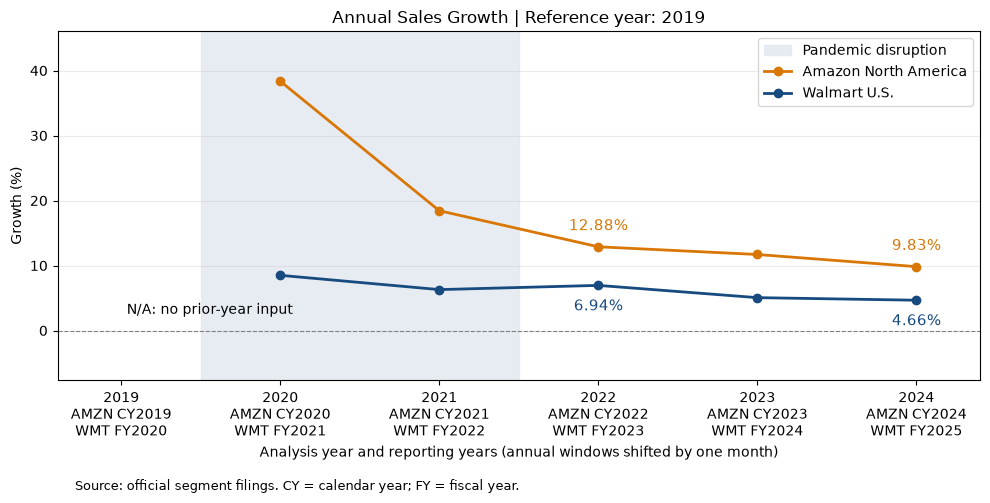

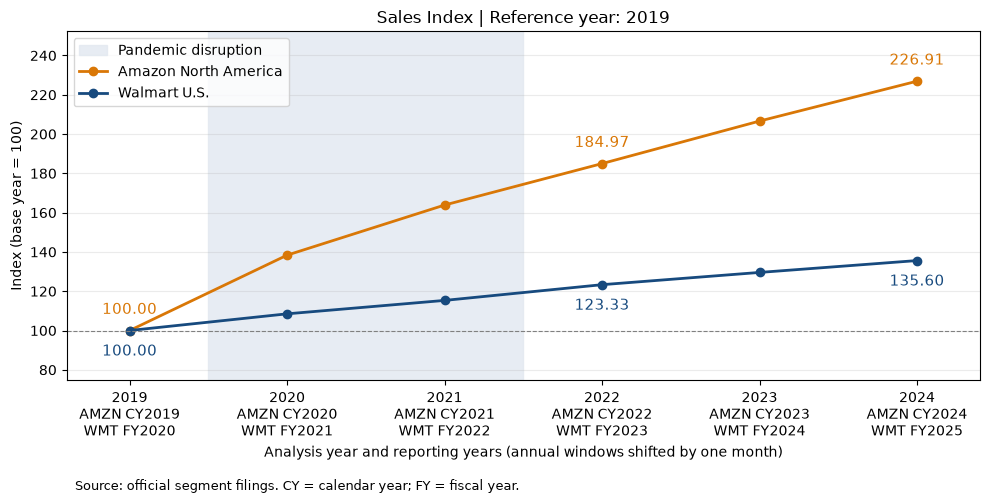

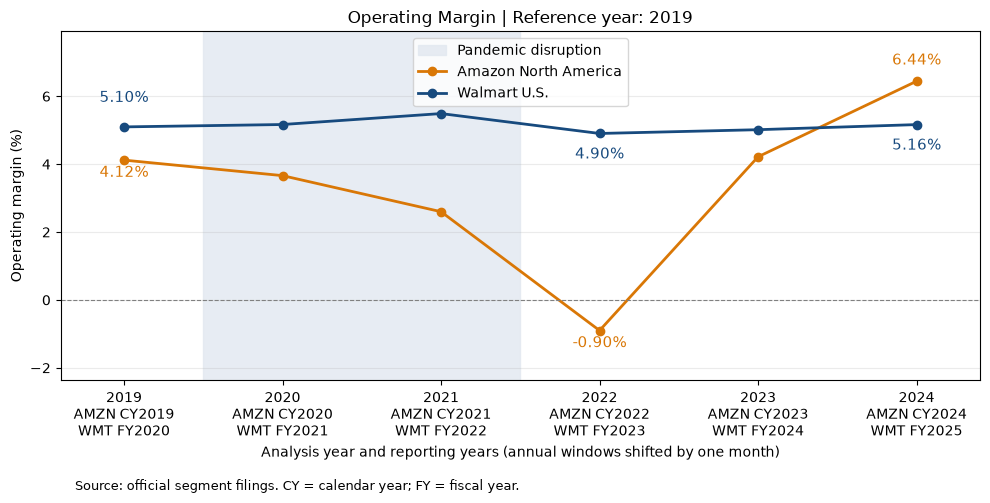

In [13]:
# Cell 02: Read the Saved Results and Create Charts

metrics_df = database.read("annual_metrics")
stage_df = database.read("stage_summary")
sales_summary_df = database.read("sales_summary")
report_builder = ReportBuilder(config, OUTPUT_DIRECTORY)
for chart in config.charts:
    report_builder.plot_chart(metrics_df, chart)


In [14]:
# Cell 03: Save the HTML Report

report_path = report_builder.write_report(metrics_df, stage_df, sales_summary_df, sql_stage_df)
print(f"Report saved: {report_path}")
print(f"Database saved: {database.database_path}")
print("All four modules are complete.")


Report saved: /Users/dadabaibaidegoose/Desktop/JupyterProject/Amazon_vs_Walmart/retail_simple_output/research_report.html
Database saved: /Users/dadabaibaidegoose/Desktop/JupyterProject/Amazon_vs_Walmart/retail_simple_output/retail_comparison.sqlite
All four modules are complete.
